# Decompose a signal to its components at different frequency bands with WPT

In this notebook we aim to test WPT for exxtracting different components of a signal based on the energy of different frequency bands. The WPT library requires python3.6+ version. The following cell checks this requirement.

In [1]:
import sys
if sys.version_info[0]+0.1*sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

Import the wavelet_transform package and required libraries.

In [2]:
sys.path.append('..')
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
import matplotlib
matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np

Specify the parameters for generating a synthetic signal and to perform wavelet packet transform.

In [3]:
# keep the same
sampling_rate = 300 # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [1,0.6,1.8] # amplitude of each sine wave
frequencies = [1,13,32] #list(np.arange(1,50)) # frequency content of signal
phases = [0,np.deg2rad(45),np.deg2rad(120)] # phase of each sine wave

duration = 50/min(frequencies) # duration of wave

fft_lim = 50 # increase value to view more of the fft plots

wavelet = 'db16'
levels = 8
mode = 'symmetric'

sort_by_energy = True # plot reconstructions of top 'n_highest' subbands by energy
n_highest = 3 # set sort_by_energy to False to plot subbands in increasing order of frequency

Generate synthetic multitonal signal with/without additive noise. We will fft the signal to double check the frequency contents.

<IPython.core.display.Javascript object>


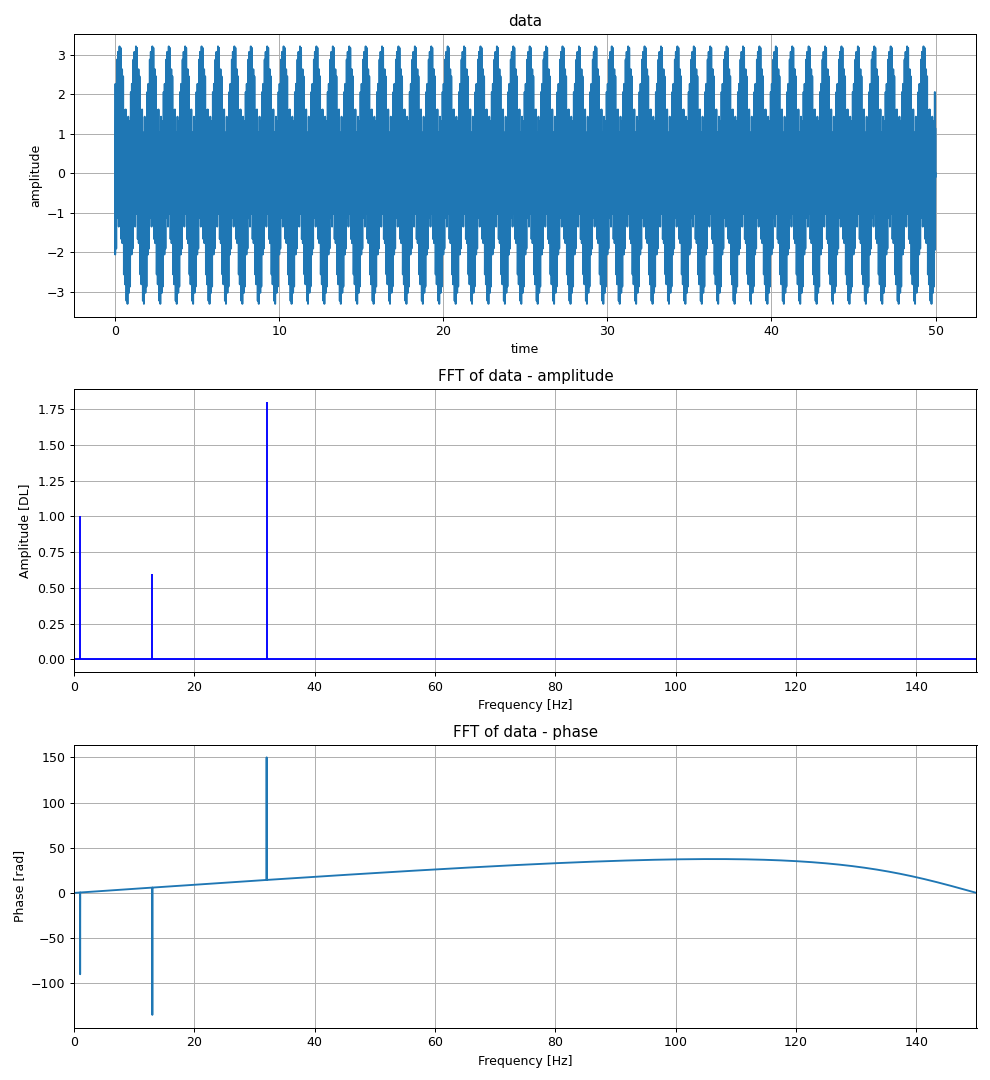

In [4]:
# generate sound wave
data,t_plot = sd.sound_wave(amplitudes,frequencies,phases,duration,sampling_rate)
signal_length = len(data)

# data += np.random.normal(0,0.2,signal_length)

# freq = np.linspace(0,sampling_rate/2, int(signal_length/2) )
fft_data = np.fft.fft(data)[0:int(signal_length/2)] / (signal_length/2)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1/sampling_rate)[0:int(signal_length/2)]

# plot sound wave and fft
fig,ax = plt.subplots(3,figsize=(11,12))
ax[0].plot(t_plot,data)
ax[0].set_title('data')
ax[0].set_xlabel('time')
ax[0].set_ylabel('amplitude')
ax[0].grid()

ax[1].stem(freq, np.abs(fft_data), 
           linefmt='b', markerfmt=" ", basefmt="-b",
           use_line_collection=True)
ax[1].set_title('FFT of data - amplitude')
ax[1].set_xlabel('Frequency [Hz]')
ax[1].set_ylabel('Amplitude [DL]')
ax[1].set_xlim(0,sampling_rate/2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data,deg=True))
ax[2].set_title('FFT of data - phase')
ax[2].set_xlabel('Frequency [Hz]')
ax[2].set_ylabel('Phase [rad]')
ax[2].set_xlim(0,sampling_rate/2)
ax[2].grid()
fig.tight_layout()
plt.show()

### Frequency content of reconstructed subbands
Decompose signal using discrete wavelet packet transform and select and reconstruct the **`n_highest`** energy components (subbands).

<div class="alert alert-block alert-warning">
    <font color=red size=6>how do you select the packets and paths for reconstruction?
</div>

<div class="alert alert-block alert-warning">
    <font color=red size=6>identify subbands with highest kurtosis and reconstruct accordingly?
</div>

<IPython.core.display.Javascript object>


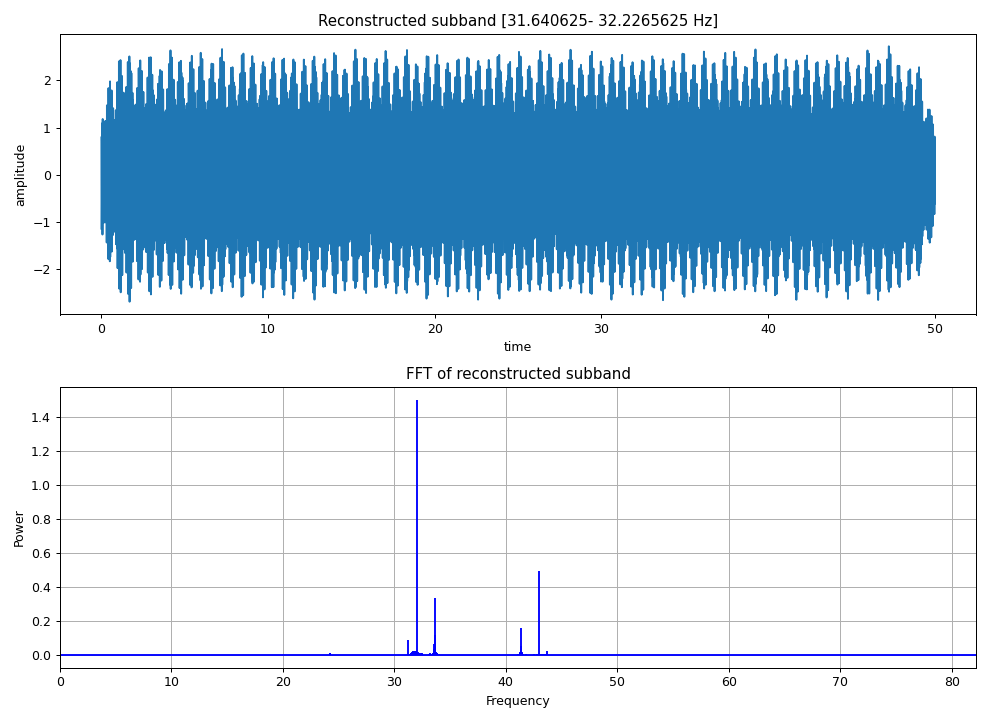

<IPython.core.display.Javascript object>


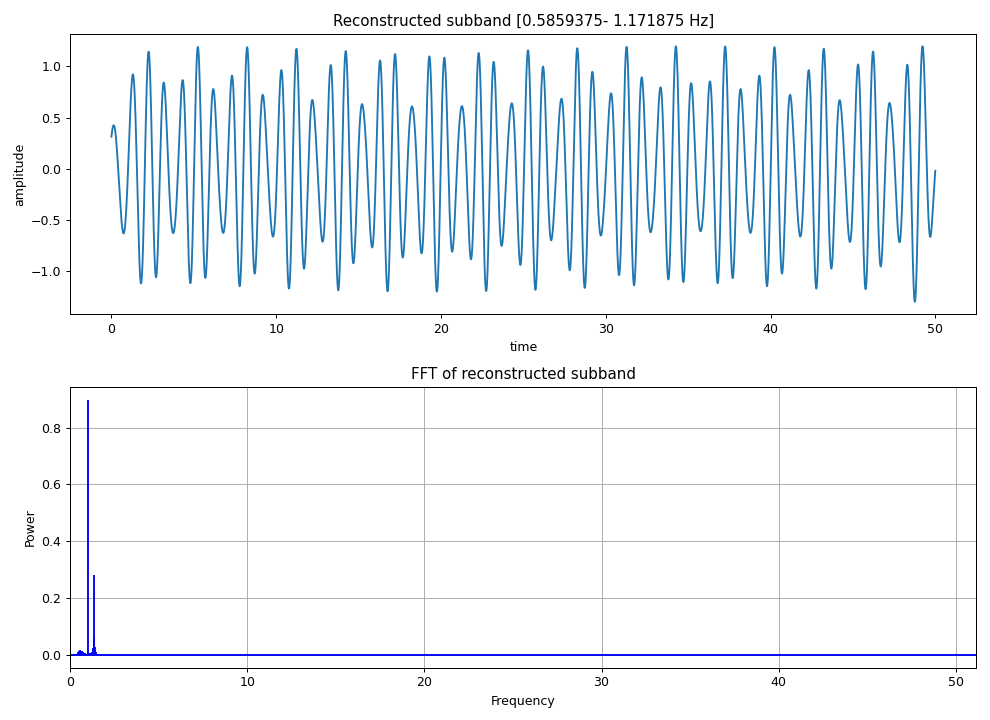

<IPython.core.display.Javascript object>


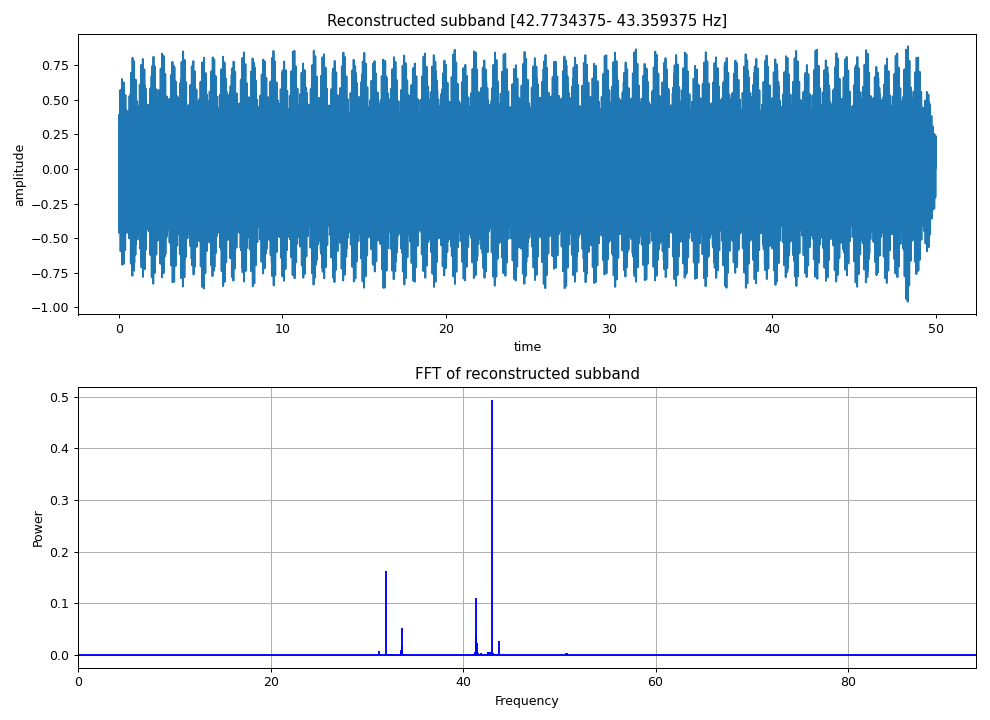

<IPython.core.display.Javascript object>


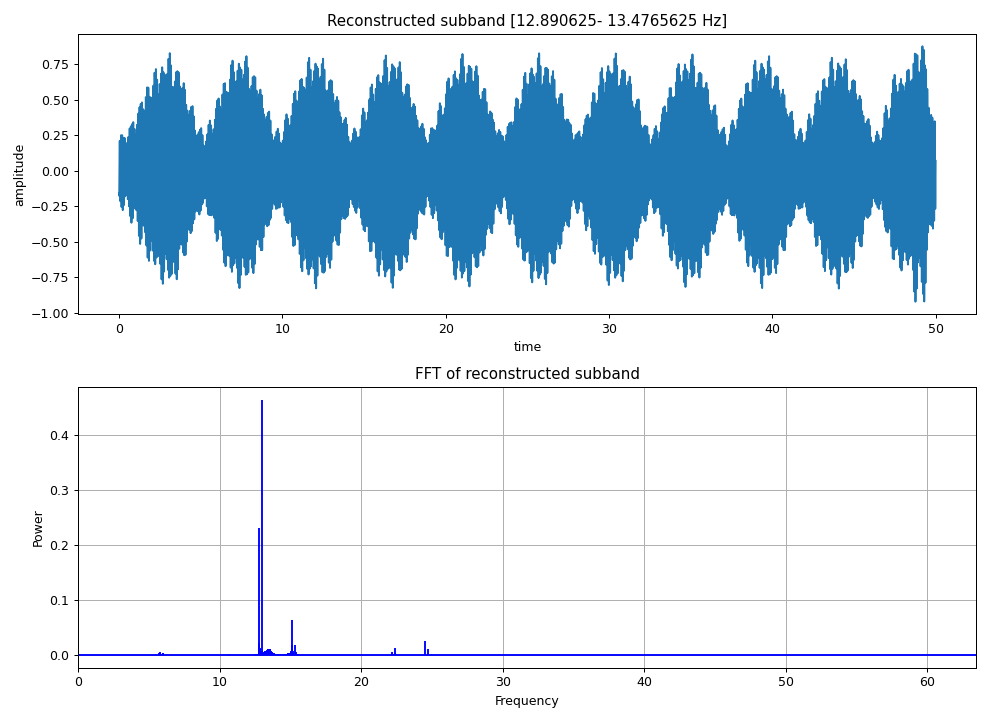

In [5]:
# WPT transform
tr_ob = wpt.dwpt(data,levels,wavelet)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
coeffs = []
rec = []

for node in tr_ob.get_level(order='freq'):
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs.append(tr_ob.nodes2data(rec_nodes))
    inverse = inv.inv_dwpt(coeffs[-1],wavelet)[:len(data)]
    inverse_signal_length = len(inverse)
    fft = np.fft.fft(inverse)[0:int(inverse_signal_length/2)]/(inverse_signal_length*0.5)
    rec.append((node,inverse,fft))

# order reconstructed waves
if sort_by_energy:
    rec.sort(key=lambda x:sum(np.array(x[1])**2),reverse=True) # SUPPRESS TO PLOT SUBBANDS IN ORDER

# plot highest energy subbands
x = np.zeros(signal_length) # track sum of highest energy subbands
for i in range(len(rec)):
    node,rec_wave,fft = rec[i] 
    if i in range(n_highest) or node.match_ids(frequencies): # highest energy + freqs of interest
        x+=rec_wave
        fig,ax = plt.subplots(2,figsize=(11,8))
        freq_r = node.frequency_range
        ax[0].plot(t_plot,rec_wave)
        ax[0].set_title(f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]" )
        ax[0].set_xlabel('time')
        ax[0].set_ylabel('amplitude')
        ax[1].stem(freq, np.abs(fft), linefmt='b', markerfmt=" ", basefmt="-b",use_line_collection=True)
        ax[1].set_title('FFT of reconstructed subband')
        ax[1].set_xlabel('Frequency')
        ax[1].set_ylabel('Power')
        ax[1].set_xlim(max(0,freq_r[0]-fft_lim),min(sampling_rate/2,freq_r[1]+fft_lim))
        ax[1].grid()
        fig.tight_layout()
        plt.show()


<div class="alert alert-block alert-warning">
    <font color=red size=6>why 4 packets are chosen when n_highest=3?
</div>

<IPython.core.display.Javascript object>


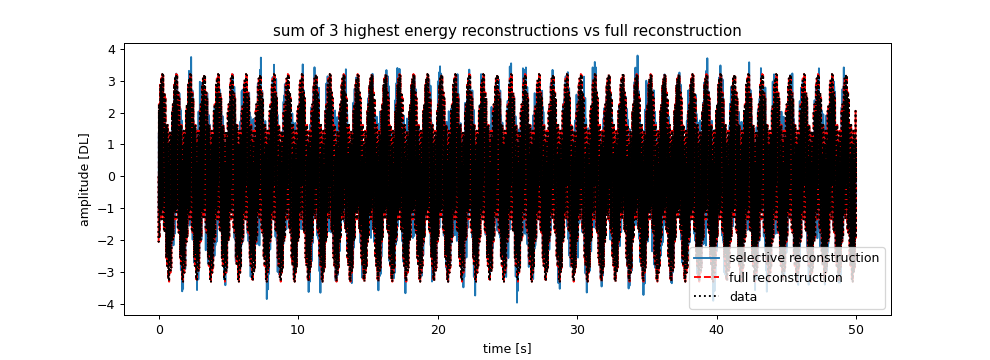

In [6]:
# plot sum of highest energy subbands
plt.figure(figsize=(11,4))
plt.plot(t_plot, x)
plt.xlabel('time [s]')
plt.ylabel('amplitude [DL]')
plt.title('sum of '+  str(n_highest) + ' highest energy reconstructions vs full reconstruction')

# plot full reconstruction
full_rec = inv.inv_dwpt(tr_ob.nodes2data(tr_ob.get_level()),wavelet)
plt.plot(t_plot,full_rec[:len(data)],'--r')
plt.plot(t_plot, data,':k')
plt.legend(['selective reconstruction','full reconstruction','data'],loc="best")
plt.show()

<IPython.core.display.Javascript object>


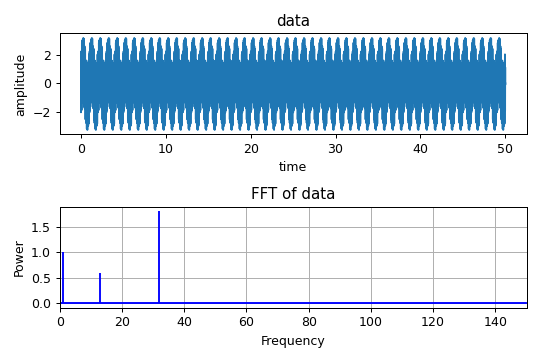

<IPython.core.display.Javascript object>


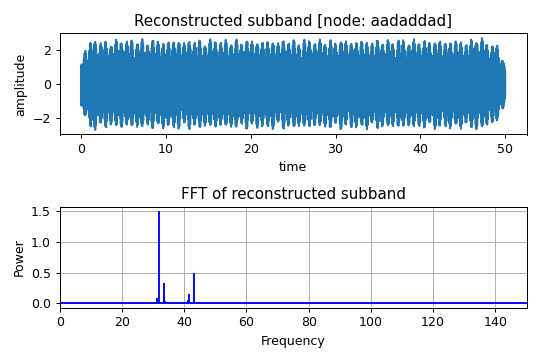

<IPython.core.display.Javascript object>


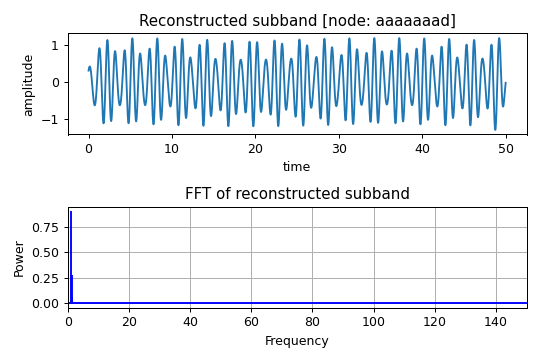

<IPython.core.display.Javascript object>


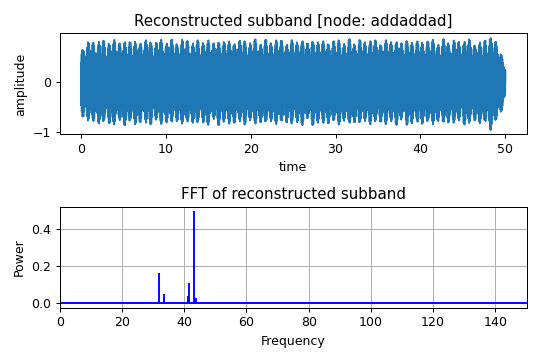

<IPython.core.display.Javascript object>


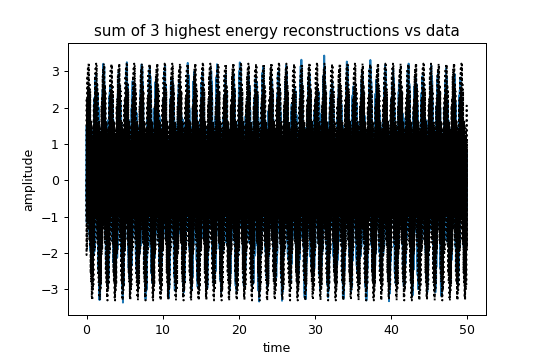

In [7]:
import pywt
# plot sound wave and fft
fig,ax = plt.subplots(2)
ax[0].plot(t_plot,data)
ax[0].set_title('data')
ax[0].set_xlabel('time')
ax[0].set_ylabel('amplitude')
ax[1].stem(freq, np.abs(fft_data), linefmt='b', markerfmt=" ", basefmt="-b",use_line_collection=True)
ax[1].set_title('FFT of data')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Power')
ax[1].set_xlim(0,sampling_rate/2)
ax[1].grid()
fig.tight_layout()
plt.show()

# transform
wp = pywt.WaveletPacket(data,wavelet,mode,maxlevel=levels)

# reconstruct each node separately
coeffs = []
rec = []

for node in wp.get_level(levels,'freq'):
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs.append(tr_ob.nodes2data(rec_nodes))
    inverse = inv.inv_dwpt(coeffs[-1],wavelet)[:len(data)]
    fft = np.fft.fft(inverse)[0:int(inverse_signal_length/2)]/(inverse_signal_length*0.5)
    rec.append((node,inverse,fft))

# order reconstructed waves
if sort_by_energy:
    rec.sort(key=lambda x:sum(np.array(x[1])**2),reverse=True) # SUPPRESS TO PLOT SUBBANDS IN ORDER

# plot highest energy subbands
x = np.zeros(len(data)) # track sum of highest energy subbands
for i in range(len(rec)):
    node,rec_wave,fft = rec[i] 
    if i in range(n_highest): # highest energy + freqs of interest
        x+=rec_wave
        fig,ax = plt.subplots(2)
        ax[0].plot(t_plot,rec_wave)
        ax[0].set_title(f'Reconstructed subband [node: {node.path}]')
        ax[0].set_xlabel('time')
        ax[0].set_ylabel('amplitude')
        ax[1].stem(freq, np.abs(fft), linefmt='b', markerfmt=" ", basefmt="-b",use_line_collection=True)
        ax[1].set_title(f'FFT of reconstructed subband')
        ax[1].set_xlabel('Frequency')
        ax[1].set_ylabel('Power')
        ax[1].set_xlim(0,sampling_rate/2)
        ax[1].grid()
        fig.tight_layout()
        plt.show()

# plot sum of highest energy subbands
plt.figure()
plt.plot(t_plot,x)
plt.xlabel('time')
plt.ylabel('amplitude')
plt.title(f'sum of {n_highest} highest energy reconstructions vs data')
plt.plot(t_plot,data,':k')
plt.show()

### testing frequency sorting algorithm

In [8]:
my_frequencies = [node.path for node in tr_ob.get_level(order='freq')]
pywt_nodes = pywt._wavelet_packets.get_graycode_order(levels)
print('my nodes ordered by frequency:',my_frequencies)
print('pywt order:                   ',pywt_nodes)
print(my_frequencies==pywt_nodes)

my nodes ordered by frequency: ['aaaaaaaa', 'aaaaaaad', 'aaaaaadd', 'aaaaaada', 'aaaaadda', 'aaaaaddd', 'aaaaadad', 'aaaaadaa', 'aaaaddaa', 'aaaaddad', 'aaaadddd', 'aaaaddda', 'aaaadada', 'aaaadadd', 'aaaadaad', 'aaaadaaa', 'aaaddaaa', 'aaaddaad', 'aaaddadd', 'aaaddada', 'aaadddda', 'aaaddddd', 'aaadddad', 'aaadddaa', 'aaadadaa', 'aaadadad', 'aaadaddd', 'aaadadda', 'aaadaada', 'aaadaadd', 'aaadaaad', 'aaadaaaa', 'aaddaaaa', 'aaddaaad', 'aaddaadd', 'aaddaada', 'aaddadda', 'aaddaddd', 'aaddadad', 'aaddadaa', 'aaddddaa', 'aaddddad', 'aadddddd', 'aaddddda', 'aadddada', 'aadddadd', 'aadddaad', 'aadddaaa', 'aadadaaa', 'aadadaad', 'aadadadd', 'aadadada', 'aadaddda', 'aadadddd', 'aadaddad', 'aadaddaa', 'aadaadaa', 'aadaadad', 'aadaaddd', 'aadaadda', 'aadaaada', 'aadaaadd', 'aadaaaad', 'aadaaaaa', 'addaaaaa', 'addaaaad', 'addaaadd', 'addaaada', 'addaadda', 'addaaddd', 'addaadad', 'addaadaa', 'addaddaa', 'addaddad', 'addadddd', 'addaddda', 'addadada', 'addadadd', 'addadaad', 'addadaaa', 'addddaa